# ML Feature Engineering

This notebook prepares a compact modeling matrix from the flattened Vulkan profile data. It shows scaling candidates, log transforms, feature reduction, and a small interpretable feature subset for downstream notebooks.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler

from src.ml_model_utils import reduce_feature_set
from src.vulkan_math_data import feature_matrix, load_ml_dataset

sns.set_theme(context="notebook", style="whitegrid")

2026-06-04 14:24:27.379049: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-06-04 14:24:27.797468: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-06-04 14:24:28.000617: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-06-04 14:24:28.002420: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-06-04 14:24:28.309163: I tensorflow/core/platform/cpu_feature_gua

In [3]:
ml_frame, diagnostics = load_ml_dataset()
X, feature_columns = feature_matrix(ml_frame)
engineered = X.copy()
for column in [c for c in engineered.columns if c.startswith("agg__")]:
    engineered[f"log1p__{column}"] = np.log1p(engineered[column])

compact = reduce_feature_set(engineered, max_features=24)
display(compact.head())
print("Original feature count:", X.shape[1])
print("Engineered feature count:", engineered.shape[1])
print("Compact feature count:", compact.shape[1])

,prop__VkPhysicalDeviceTimelineSemaphorePropertiesKHR__maxTimelineSemaphoreValueDifference,prop__VkPhysicalDeviceVulkan12Properties__maxTimelineSemaphoreValueDifference,prop__VkPhysicalDeviceMaintenance4PropertiesKHR__maxBufferSize,prop__VkPhysicalDeviceVulkan13Properties__maxBufferSize,prop__VkPhysicalDeviceMaintenance3PropertiesKHR__maxMemoryAllocationSize,prop__VkPhysicalDeviceVulkan11Properties__maxMemoryAllocationSize,prop__VkPhysicalDeviceTransformFeedbackPropertiesEXT__maxTransformFeedbackBufferSize,prop__VkPhysicalDeviceExtendedSparseAddressSpacePropertiesNV__extendedSparseAddressSpaceSize,prop__VkPhysicalDeviceProperties__limits__sparseAddressSpaceSize,prop__VkPhysicalDeviceDescriptorBufferPropertiesEXT__resourceDescriptorBufferAddressSpaceSize,...,prop__VkPhysicalDeviceNestedCommandBufferPropertiesEXT__maxCommandBufferNestingLevel,prop__VkPhysicalDeviceProperties__limits__maxMemoryAllocationCount,prop__VkPhysicalDeviceProperties__limits__maxFragmentCombinedOutputResources,prop__VkPhysicalDeviceDeviceGeneratedCommandsPropertiesNV__maxIndirectCommandsTokenOffset,prop__VkPhysicalDeviceDeviceGeneratedCommandsPropertiesNV__maxIndirectCommandsStreamStride,prop__VkPhysicalDeviceMultiDrawPropertiesEXT__maxMultiDrawCount,prop__VkPhysicalDeviceDescriptorIndexingPropertiesEXT__maxPerStageUpdateAfterBindResources,prop__VkPhysicalDeviceDescriptorIndexingPropertiesEXT__maxUpdateAfterBindDescriptorsInAllPools,prop__VkPhysicalDeviceMaintenance3PropertiesKHR__maxPerSetDescriptors,prop__VkPhysicalDeviceVulkan12Properties__maxPerStageUpdateAfterBindResources
0,2.147484e+09,2.147484e+09,0.0,0.0,4.292870e+09,4.292870e+09,9.223372e+18,0.0,1.099510e+12,0.0,...,0.0,4096.0,16.0,4.294967e+09,4.294967e+09,0.0,4.294967e+09,4.294967e+09,4.294967e+09,4.294967e+09
1,2.147484e+09,2.147484e+09,0.0,0.0,4.292870e+09,4.292870e+09,9.223372e+18,0.0,1.099510e+12,0.0,...,0.0,4096.0,16.0,4.294967e+09,4.294967e+09,0.0,4.294967e+09,4.294967e+09,4.294967e+09,4.294967e+09
2,2.147484e+09,2.147484e+09,0.0,0.0,4.292870e+09,4.292870e+09,9.223372e+18,0.0,1.099510e+12,0.0,...,0.0,4096.0,16.0,4.294967e+09,4.294967e+09,0.0,4.294967e+09,4.294967e+09,4.294967e+09,4.294967e+09
3,2.147484e+09,2.147484e+09,0.0,0.0,4.292870e+09,4.292870e+09,9.223372e+18,0.0,1.099510e+12,0.0,...,0.0,4096.0,16.0,4.294967e+09,4.294967e+09,0.0,4.294967e+09,4.294967e+09,4.294967e+09,4.294967e+09
4,2.147484e+09,2.147484e+09,0.0,0.0,4.292870e+09,4.292870e+09,9.223372e+18,0.0,1.099510e+12,0.0,...,0.0,4096.0,16.0,4.294967e+09,4.294967e+09,0.0,4.294967e+09,4.294967e+09,4.294967e+09,4.294967e+09


Original feature count: 830
Engineered feature count: 835
Compact feature count: 24


In [4]:
scaled = pd.DataFrame(
    StandardScaler().fit_transform(compact),
    columns=compact.columns,
    index=compact.index,
)
summary = pd.DataFrame(
    {
        "feature": compact.columns,
        "variance": compact.var().to_numpy(),
        "mean_after_scaling": scaled.mean().to_numpy(),
    }
)
display(summary.sort_values("variance", ascending=False).head(15))

,feature,variance,mean_after_scaling
0,prop__VkPhysicalDeviceTimelineSemaphorePropert...,1.468231e+37,-7.793887e-17
1,prop__VkPhysicalDeviceVulkan12Properties__maxT...,1.433025e+37,1.558777e-16
2,prop__VkPhysicalDeviceMaintenance4PropertiesKH...,1.139926e+37,2.597962e-17
3,prop__VkPhysicalDeviceVulkan13Properties__maxB...,1.139926e+37,5.195925e-17
4,prop__VkPhysicalDeviceMaintenance3PropertiesKH...,8.322996e+36,-5.195925e-17
5,prop__VkPhysicalDeviceVulkan11Properties__maxM...,8.322996e+36,-7.793887e-17
6,prop__VkPhysicalDeviceTransformFeedbackPropert...,6.304057e+36,0.000000e+00
7,prop__VkPhysicalDeviceExtendedSparseAddressSpa...,6.034148e+27,-5.195925e-17
8,prop__VkPhysicalDeviceProperties__limits__spar...,6.956085e+26,-1.298981e-17
9,prop__VkPhysicalDeviceDescriptorBufferProperti...,2.780963e+23,2.597962e-17


/tmp/ipykernel_2048/2863542194.py:6: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


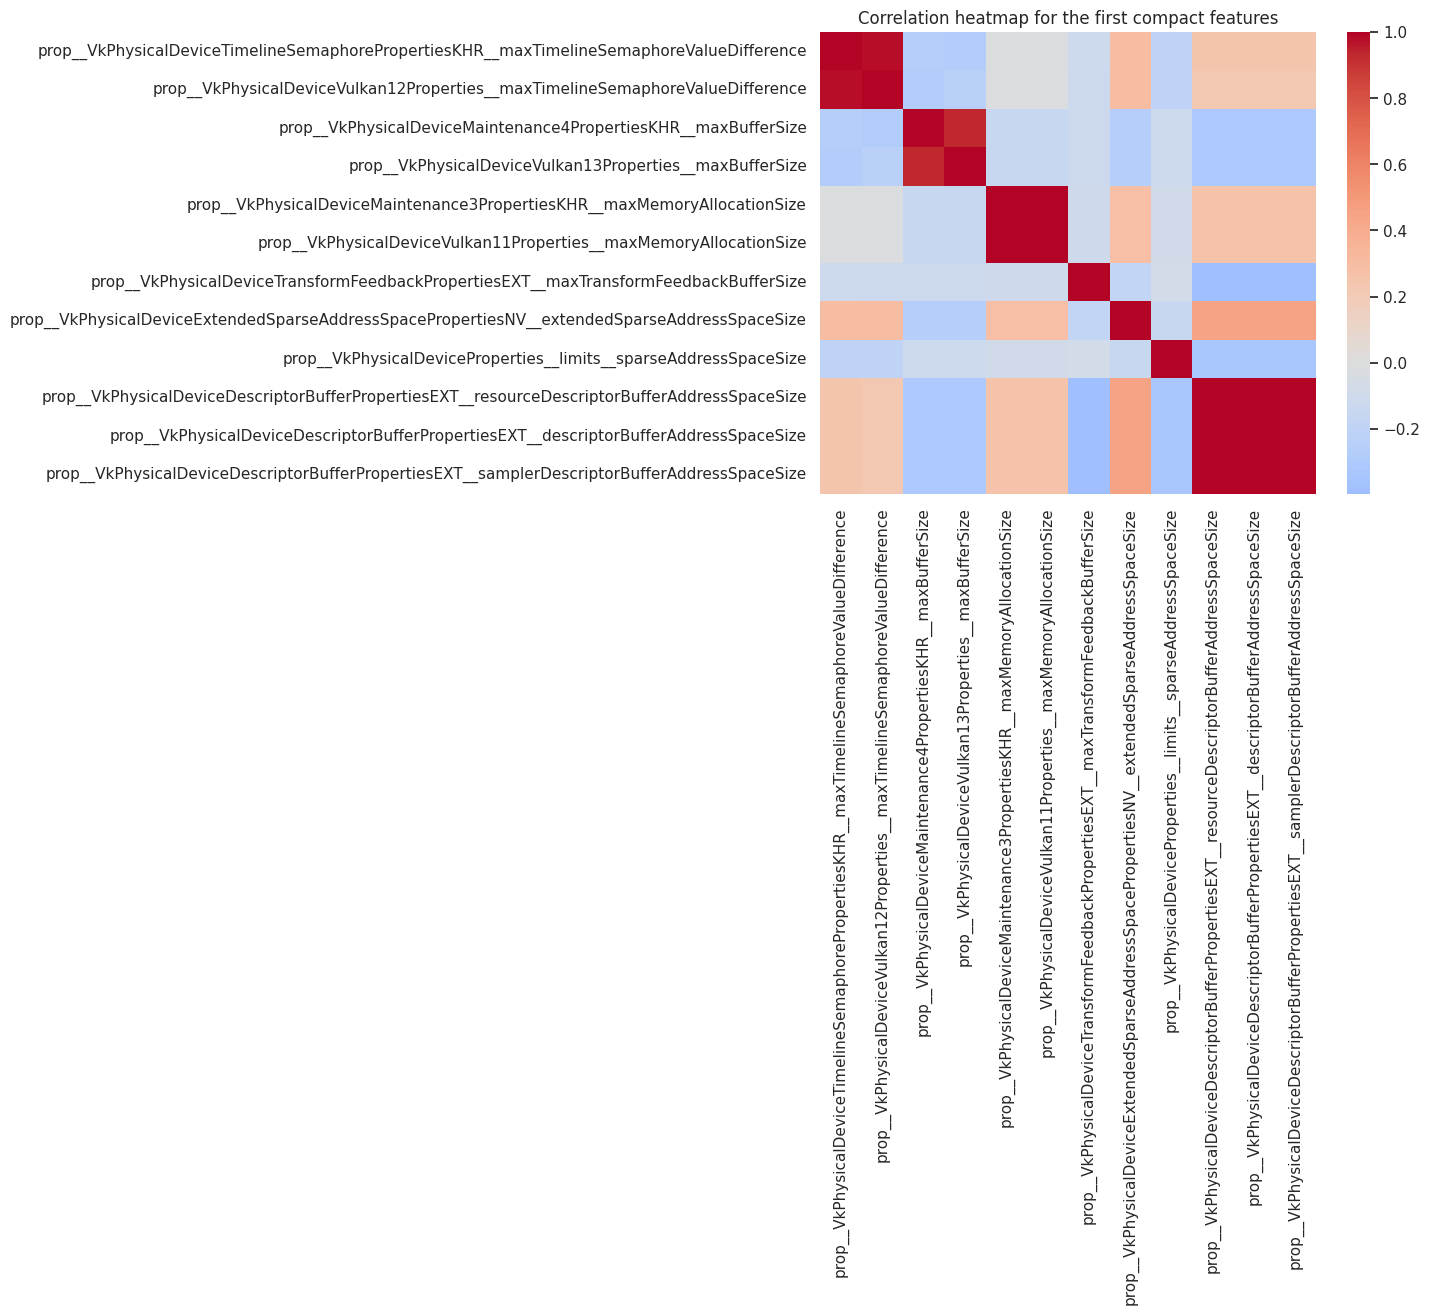

In [5]:
if compact.shape[1] >= 2:
    corr = compact.corr().fillna(0)
    plt.figure(figsize=(8, 6))
    sns.heatmap(corr.iloc[:12, :12], cmap="coolwarm", center=0)
    plt.title("Correlation heatmap for the first compact features")
    plt.tight_layout()
    plt.show()
else:
    print(
        "Correlation heatmap skipped because fewer than two compact features are available."
    )

In [6]:
interpretable_columns = [
    column for column in compact.columns if column.startswith(("agg__", "log1p__agg__"))
]
display(compact[interpretable_columns].head())

""
0
1
2
3
4
